<a href="https://colab.research.google.com/github/zk025815-beep/ML-Foundations-From-Scratch/blob/main/Messy_Data_Pipeline_RF_XGBoost_SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Random Forest (ROC-AUC: 0.925) ===
              precision    recall  f1-score   support

           0       0.87      0.91      0.89       127
           1       0.83      0.75      0.79        73

    accuracy                           0.85       200
   macro avg       0.85      0.83      0.84       200
weighted avg       0.85      0.85      0.85       200

=== XGBoost (ROC-AUC: 0.923) ===
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       127
           1       0.82      0.81      0.81        73

    accuracy                           0.86       200
   macro avg       0.86      0.85      0.85       200
weighted avg       0.86      0.86      0.86       200



/tmp/ipykernel_1689/1456093232.py:98: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_df)


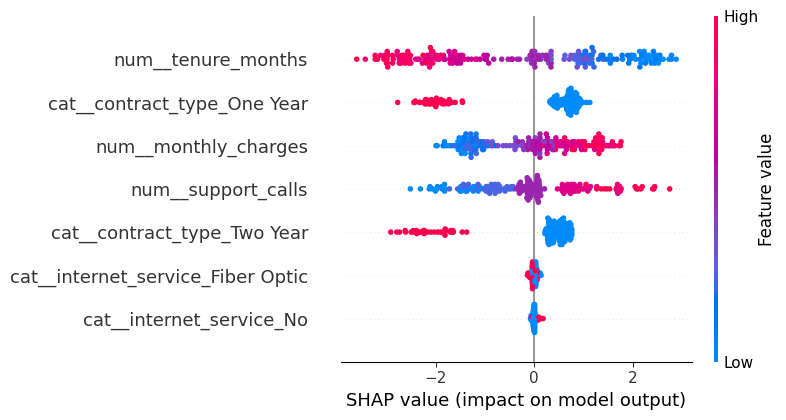

In [1]:
# Install shap and xgboost if not already installed in Colab
# !pip install xgboost shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Create a Realistic Messy Tabular Dataset (Customer Churn: 1000 rows)
np.random.seed(42)
n = 1000
df = pd.DataFrame({
    'tenure_months': np.random.randint(1, 72, n).astype(float),
    'monthly_charges': np.random.uniform(20, 120, n),
    'support_calls': np.random.poisson(2, n).astype(float),
    'contract_type': np.random.choice(['Month-to-Month', 'One Year', 'Two Year'], n, p=[0.5, 0.3, 0.2]),
    'internet_service': np.random.choice(['Fiber Optic', 'DSL', 'No'], n, p=[0.45, 0.35, 0.2])
})

# Target logic: High churn if Month-to-Month, high support calls, low tenure, high charges
risk = (
    (df['contract_type'] == 'Month-to-Month') * 1.5 +
    (df['support_calls'] * 0.45) -
    (df['tenure_months'] * 0.04) +
    (df['monthly_charges'] * 0.015) +
    np.random.normal(0, 0.5, n)
)
df['churn'] = (risk > 1.8).astype(int)

# Inject realistic "Messiness" (Missing NaN values in numerical & categorical columns)
df.loc[np.random.choice(n, 60, replace=False), 'monthly_charges'] = np.nan
df.loc[np.random.choice(n, 40, replace=False), 'tenure_months'] = np.nan
df.loc[np.random.choice(n, 30, replace=False), 'contract_type'] = np.nan

# 2. Split FIRST (Before any imputation or scaling to prevent Data Leakage!)
X = df.drop('churn', axis=1)
y = df['churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 3. Build Scikit-Learn Preprocessing Pipeline
num_cols = ['tenure_months', 'monthly_charges', 'support_calls']
cat_cols = ['contract_type', 'internet_service']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # Median is robust to outliers!
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# 4. Train & Compare Random Forest (Bagging) vs. XGBoost (Boosting)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric='logloss', random_state=42)
}

trained_pipelines = {}
for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('clf', model)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    print(f"=== {name} (ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}) ===")
    print(classification_report(y_test, y_pred))

# 5. Phase 3: SHAP Explainability on XGBoost
xgb_pipe = trained_pipelines["XGBoost"]
X_test_transformed = xgb_pipe.named_steps['prep'].transform(X_test)
feature_names = xgb_pipe.named_steps['prep'].get_feature_names_out()
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

explainer = shap.TreeExplainer(xgb_pipe.named_steps['clf'])
shap_values = explainer.shap_values(X_test_df)

# Plot Global & Local Feature Impact
shap.summary_plot(shap_values, X_test_df)